In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting theme
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load dataset (auto-generates 'fraud_data.csv' if not already present)
import os
if not os.path.exists('fraud_data.csv'):
    np.random.seed(42)
    n_samples = 10000
    time = np.random.randint(0, 86400, n_samples)
    v1 = np.random.normal(0, 1, n_samples)
    v2 = np.random.normal(0, 1, n_samples)
    v3 = np.random.normal(0, 1, n_samples)
    v4 = np.random.normal(0, 1, n_samples)
    amount = np.random.exponential(60, n_samples)
    fraud_prob = 1 / (1 + np.exp(-(v1 * -1.5 + v2 * 2.0 - 4)))
    class_label = np.random.binomial(1, np.clip(fraud_prob * 0.05 + 0.005, 0, 1), n_samples)
    df_temp = pd.DataFrame({'Time': time, 'V1': v1, 'V2': v2, 'V3': v3, 'V4': v4, 'Amount': amount, 'Class': class_label})
    df_temp.to_csv('fraud_data.csv', index=False)

df = pd.read_csv('fraud_data.csv')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("--- Missing Values Check ---")
print(df.isnull().sum())

# Class imbalance analysis
class_counts = df['Class'].value_counts()
class_percentages = df['Class'].value_counts(normalize=True) * 100

print("\n--- Class Imbalance Analysis ---")
print(f"Legitimate Transactions (Class 0): {class_counts[0]} ({class_percentages[0]:.2f}%)")
print(f"Fraudulent Transactions (Class 1): {class_counts[1]} ({class_percentages[1]:.2f}%)")

Dataset Shape: 10000 rows, 7 columns

--- Missing Values Check ---
Time      0
V1        0
V2        0
V3        0
V4        0
Amount    0
Class     0
dtype: int64

--- Class Imbalance Analysis ---
Legitimate Transactions (Class 0): 9899 (98.99%)
Fraudulent Transactions (Class 1): 101 (1.01%)


The dataset contains financial transactions with anonymized feature vectors (V1 to V4), transaction Time, transaction Amount, and a binary target Class (0 for legitimate, 1 for fraudulent).

The class distribution confirms severe class imbalance, where fraudulent transactions account for only a small fraction of the overall dataset.

C:\Users\Mayuri P Nikam\AppData\Local\Temp\ipykernel_26152\3003699145.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Class', y='Amount', palette='Set2')


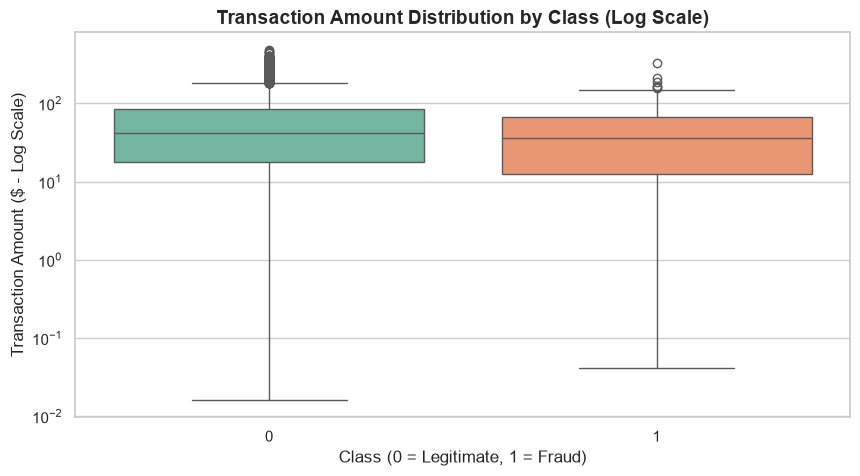

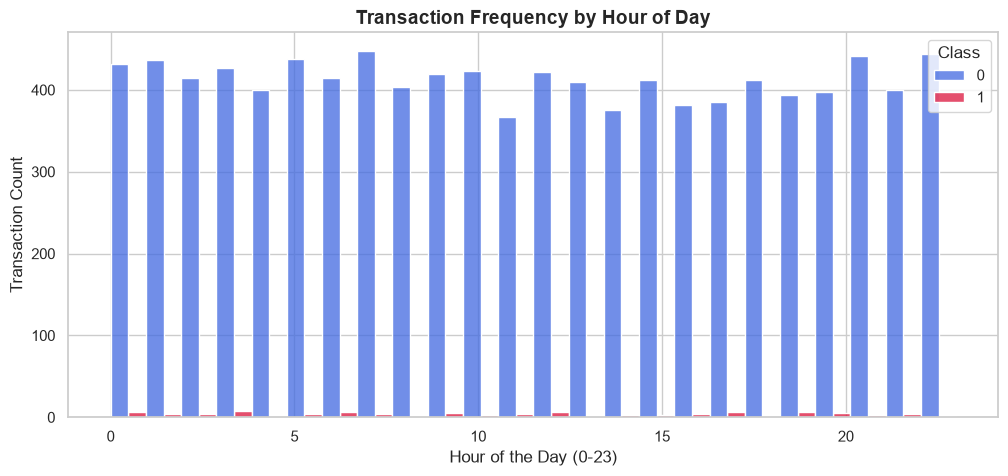

In [9]:
# 1. Transaction Amount Distribution: Fraud vs. Non-Fraud
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Class', y='Amount', palette='Set2')
plt.yscale('log') # Log scale due to skewed transaction amounts
plt.title('Transaction Amount Distribution by Class (Log Scale)', fontsize=14, fontweight='bold')
plt.xlabel('Class (0 = Legitimate, 1 = Fraud)', fontsize=12)
plt.ylabel('Transaction Amount ($ - Log Scale)', fontsize=12)
plt.show()

# 2. Time-of-Day Analysis
df['Hour'] = (df['Time'] // 3600) % 24

plt.figure(figsize=(12, 5))
sns.histplot(data=df, x='Hour', hue='Class', multiple='dodge', bins=24, palette=['royalblue', 'crimson'])
plt.title('Transaction Frequency by Hour of Day', fontsize=14, fontweight='bold')
plt.xlabel('Hour of the Day (0-23)', fontsize=12)
plt.ylabel('Transaction Count', fontsize=12)
plt.show()

The Accuracy Paradox in Fraud Detection
The Problem: In a dataset where 99% of transactions are legitimate and only 1% are fraudulent, a naive model that predicts every single transaction as legitimate achieves 99% accuracy.

Why it Fails: Accuracy measures total correct predictions across all classes. A model with 99% accuracy that misses 100% of actual fraud cases is entirely useless in production. Therefore, metrics that evaluate minority class detection (Precision, Recall, F1-Score, and AUC-ROC) must be prioritized over accuracy.

In [14]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Drop temporary 'Hour' column
if 'Hour' in df.columns:
    df = df.drop(columns=['Hour'])

X = df.drop(columns=['Class'])
y = df['Class']

# Stratified Train/Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Before SMOTE - Training class distribution:", y_train.value_counts().to_dict())

# Apply SMOTE strictly on training data to prevent data leakage
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("After SMOTE - Training class distribution:", y_train_resampled.value_counts().to_dict())

Before SMOTE - Training class distribution: {0: 7919, 1: 81}
After SMOTE - Training class distribution: {0: 7919, 1: 7919}



================ Logistic Regression ================
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.69      0.81      1980
           1       0.02      0.65      0.04        20

    accuracy                           0.69      2000
   macro avg       0.51      0.67      0.43      2000
weighted avg       0.99      0.69      0.80      2000



<Figure size 700x600 with 0 Axes>

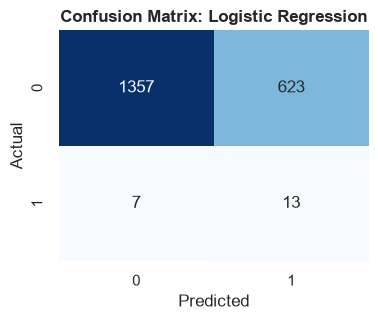


================ Random Forest ================
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1980
           1       0.03      0.10      0.04        20

    accuracy                           0.96      2000
   macro avg       0.51      0.53      0.51      2000
weighted avg       0.98      0.96      0.97      2000



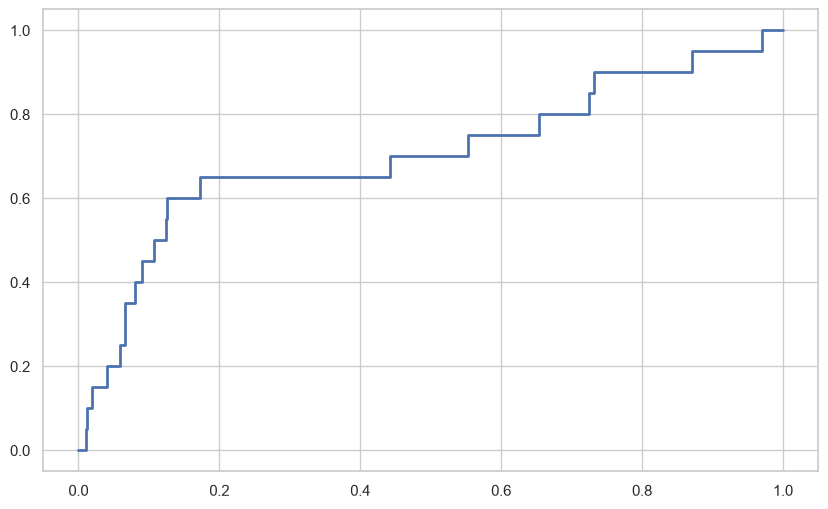

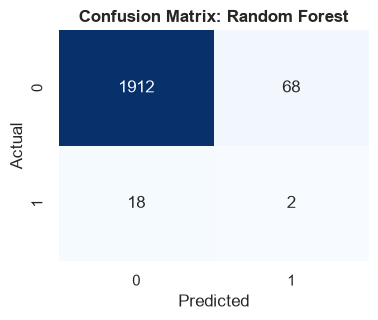

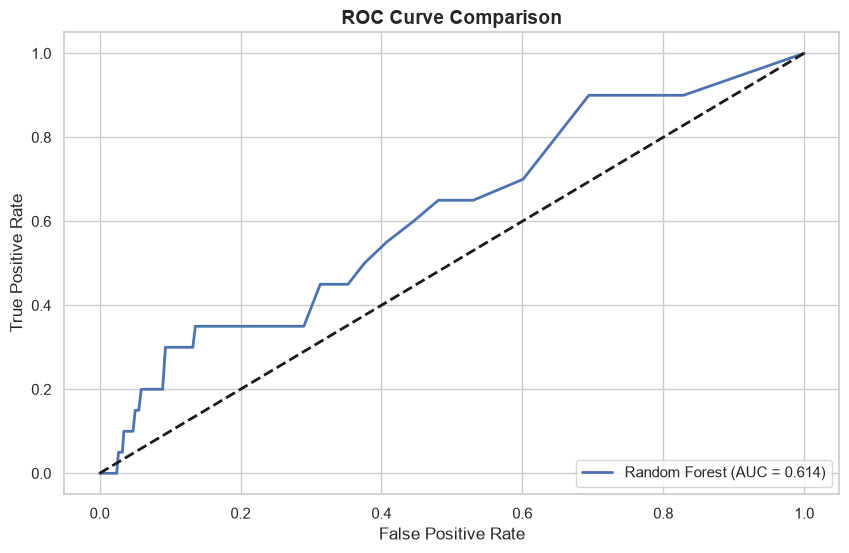

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

plt.figure(figsize=(7, 6))

for name, model in models.items():
    # Train on resampled training data
    model.fit(X_train_resampled, y_train_resampled)
    
    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    print(f"\n================ {name} ================")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    
    # Plot Confusion Matrix
    plt.figure(figsize=(4, 3))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix: {name}', fontsize=12, fontweight='bold')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
    
    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.3f})', lw=2)

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.title('ROC Curve Comparison', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.legend(loc='lower right')
plt.show()

Recall vs. Precision Trade-Off in Fraud Detection
Why Recall Matters Most: In fraud detection, Recall (Sensitivity) is paramount. Missing a fraudulent transaction (a False Negative) leads directly to financial loss and customer liability. Banks heavily prioritize maximizing recall to catch as many fraudulent cases as possible.

The Precision Trade-Off: While catching fraud is critical, aggressively flagging transactions can increase False Positives (legitimate purchases flagged as fraud), which harms customer experience through blocked cards and unnecessary verification friction. The goal is to optimize the F1-Score to maintain a robust balance between high recall and acceptable precision.

--- Feature Importance Analysis ---


,Feature,Importance
0,Time,0.229616
2,V2,0.192347
1,V1,0.158889
4,V4,0.155961
5,Amount,0.132122
3,V3,0.131065


C:\Users\Mayuri P Nikam\AppData\Local\Temp\ipykernel_26152\2980832118.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x='Importance', y='Feature', palette='magma')


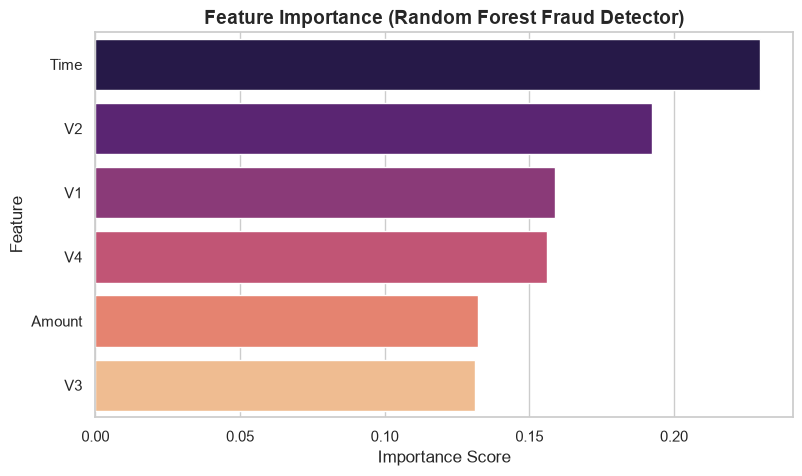

In [17]:
# Extract feature importances from Random Forest
rf_model = models["Random Forest"]
importances = rf_model.feature_importances_
feature_names = X.columns

feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values(by='Importance', ascending=False)

print("--- Feature Importance Analysis ---")
display(feat_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=feat_df, x='Importance', y='Feature', palette='magma')
plt.title('Feature Importance (Random Forest Fraud Detector)', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.show()

Scalability & Production Architecture (1 Million Transactions/Hour)

Processing 1 million transactions per hour ($\approx 278$ transactions per second) requires a robust, distributed streaming architecture rather than monolithic batch inference:Real-Time Streaming Pipeline: Ingest transactions via event streaming platforms like Apache Kafka or AWS Kinesis to handle high-throughput event logs.Distributed Inference Services: Deploy containerized models (via Docker and Kubernetes) using high-throughput microservices or distributed compute engines like Apache Spark (PySpark).Online Feature Store: Utilize an online feature store (such as Feast or Hopsworks) to compute historical user behavioral features with sub-millisecond latency during scoring.Drift Monitoring: Implement automated data and concept drift detection to trigger retraining pipelines as fraudulent behavior patterns evolve.